# Informe de resultados de tratamiento de imagen

Percepción Computacional · Semana 8

Cristian Camilo Alarcon Delgadillo, Brayan Arley Saenz Cortes y Jonathan David Llanceros Bello.

Docente: Mónica María Fonseca Vigoya.

Este cuaderno ejecuta el mismo script que el proyecto de VS Code. Incluye cinco originales, diagnóstico, tratamiento y evaluación. Las salidas se generan al ejecutar las celdas; las capturas de VS Code se conservan por separado.

## 1 Preparación
En Colab se clona el repositorio público; en VS Code se usa la copia local. No se modifican los originales.

In [1]:
from pathlib import Path
import subprocess
import sys

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    ROOT = Path("/content/TRATAMIENTO_DE_IMAGENES-")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/Camilo19P8/TRATAMIENTO_DE_IMAGENES-.git", str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

assert (ROOT / "src/practica.py").exists(), "Abra el notebook desde la carpeta del repositorio"
subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")], check=True)
print("Proyecto:", ROOT)

Proyecto: C:\Users\calar\Documents\Codex\2026-10-12\mir\outputs\TRATAMIENTO_DE_IMAGENES-


## 2 Diagnóstico y tratamiento
El script mide resolución, canales, formato, tamaño, brillo medio, contraste, varianza del Laplaciano y Tenengrad. El tratamiento seleccionado es una máscara de enfoque en luminancia con cantidad 0.8 y sigma 1.2.

In [2]:
run = subprocess.run([sys.executable, str(ROOT / "src/practica.py")], check=True, capture_output=True, text=True, encoding="utf-8", errors="replace")
print(run.stdout)

Cinco im�genes analizadas. Resultados escritos en resultados/.
01_referencia.jpeg: brillo=124.66; contraste=64.54; Laplaciano=548.53
02_iluminacion.jpeg: brillo=187.41; contraste=55.50; Laplaciano=368.33
03_desenfoque.jpeg: brillo=121.84; contraste=56.63; Laplaciano=54.23
04_fondo_complejo.jpeg: brillo=110.79; contraste=61.53; Laplaciano=457.29
05_angulo.jpeg: brillo=117.32; contraste=64.07; Laplaciano=481.44
I3: Laplaciano 54.23 -> 149.05



In [3]:
import csv
from IPython.display import display, HTML, Image

def mostrar_tabla(nombre):
    with (ROOT / "resultados" / nombre).open(encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))
    import html
    markup = "<table border=1 cellpadding=6>"
    for i, row in enumerate(rows):
        tag = "th" if i == 0 else "td"
        markup += "<tr>" + "".join(f"<{tag}>{html.escape(value)}</{tag}>" for value in row) + "</tr>"
    display(HTML(markup + "</table>"))

mostrar_tabla("diagnostico.csv")

archivo,condicion,ancho,alto,canales,formato,bytes,brillo,contraste,laplaciano,tenengrad,oscuros_pct,claros_pct,roi_brillo,roi_contraste,roi_laplaciano,roi_tenengrad,roi_oscuros_pct,roi_claros_pct
01_referencia.jpeg,Referencia,1600,902,3,JPEG,149482,124.66398350886918,64.53505529265558,548.5283030264031,8775.509047949003,0.01309589800443459,0.04649390243902439,42.076385498046875,41.70416990040516,644.9568340843543,15047.329162597656,0.0030517578125,0.006103515625
02_iluminacion.jpeg,Iluminación declarada baja,1600,902,3,JPEG,156219,187.40918860864744,55.49962651907518,368.33418782555714,8151.722839523281,0.0,0.22976718403547675,116.68951416015625,50.19314292401036,579.4923808490857,18283.074279785156,0.0,0.0640869140625
03_desenfoque.jpeg,Desenfoque o movimiento,1600,901,3,JPEG,75612,121.83933546059933,56.63345301783884,54.22782525247056,1456.9280008324085,0.0,0.007838512763596005,70.24505615234375,30.0587682231254,58.49873336777091,2316.2102661132812,0.0,0.0
04_fondo_complejo.jpeg,Fondo complejo,1600,902,3,JPEG,149550,110.79469650776053,61.527441891745745,457.28678165126246,7359.468593403548,0.0001385809312638581,0.07005266075388027,54.434173583984375,34.35558845222389,236.40598399098963,6405.7152099609375,0.0,0.0
05_angulo.jpeg,Cambio de ángulo,1600,902,3,JPEG,121820,117.32338068181818,64.07202432993809,481.43516972689906,4942.0353381374725,0.009631374722838138,0.0012472283813747228,42.689544677734375,36.392310878492744,776.6021804660559,9716.438110351562,0.0244140625,0.0


## 3 Fotografías propias y mismo objeto
La lata negra Monster de la fila superior es el objeto común. Los recortes manuales se normalizan a 128 × 256 píxeles para el diagnóstico exploratorio. El cambio de perspectiva impide una comparación geométrica exacta.

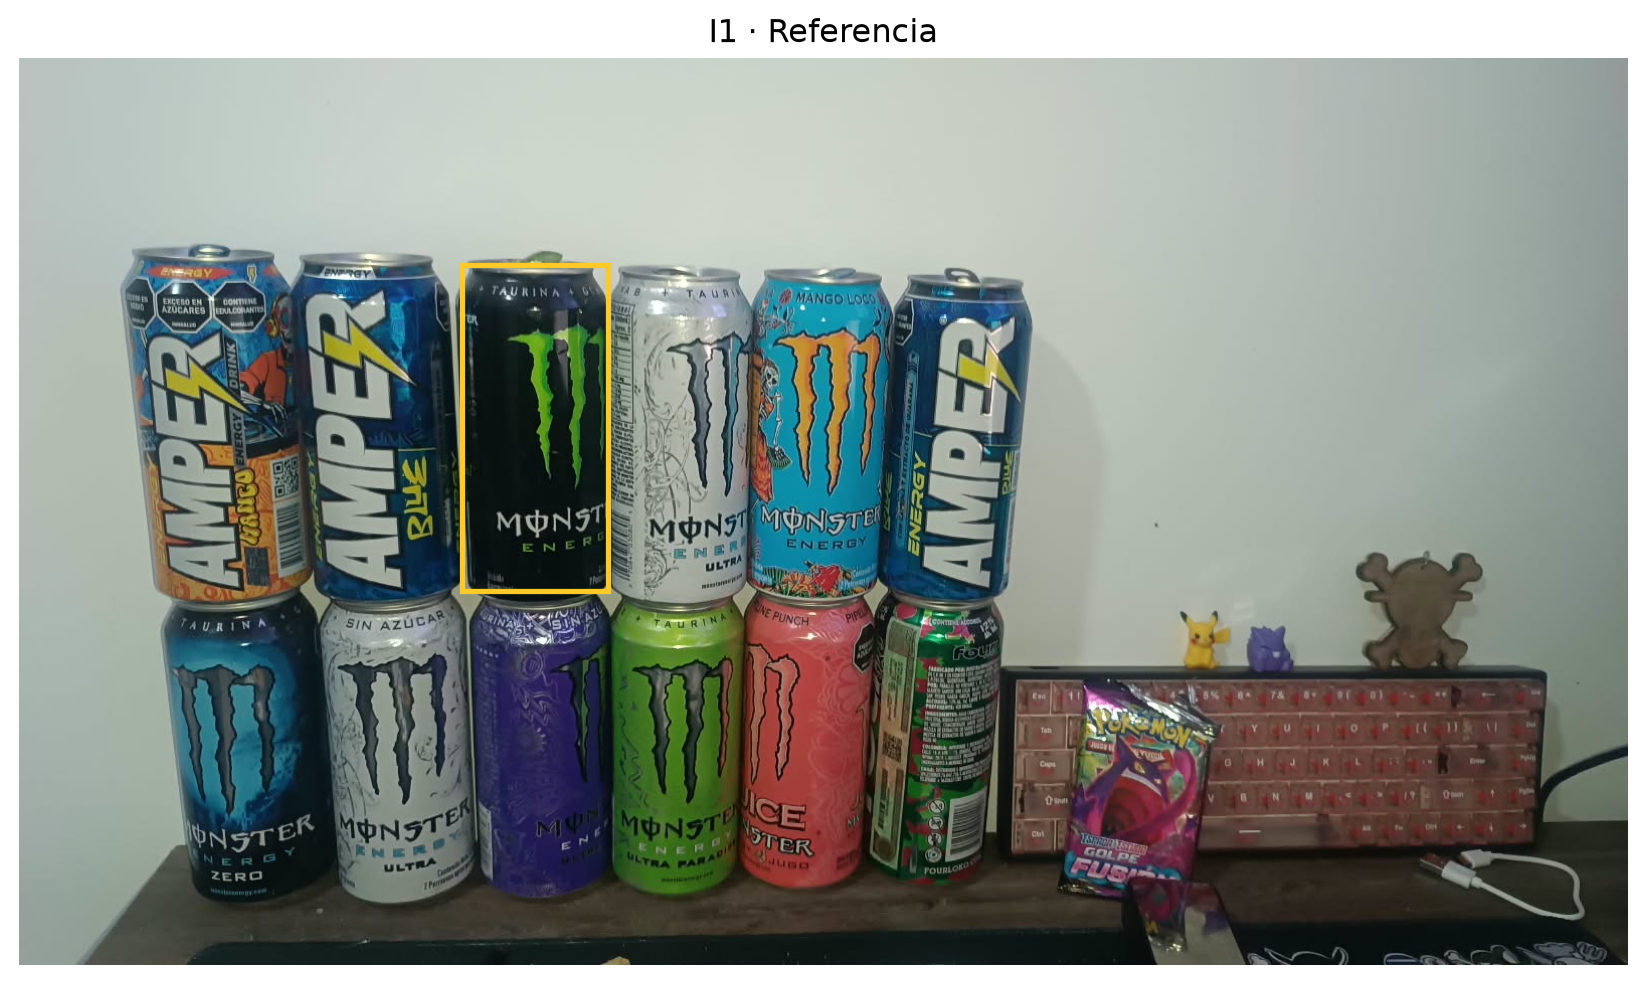

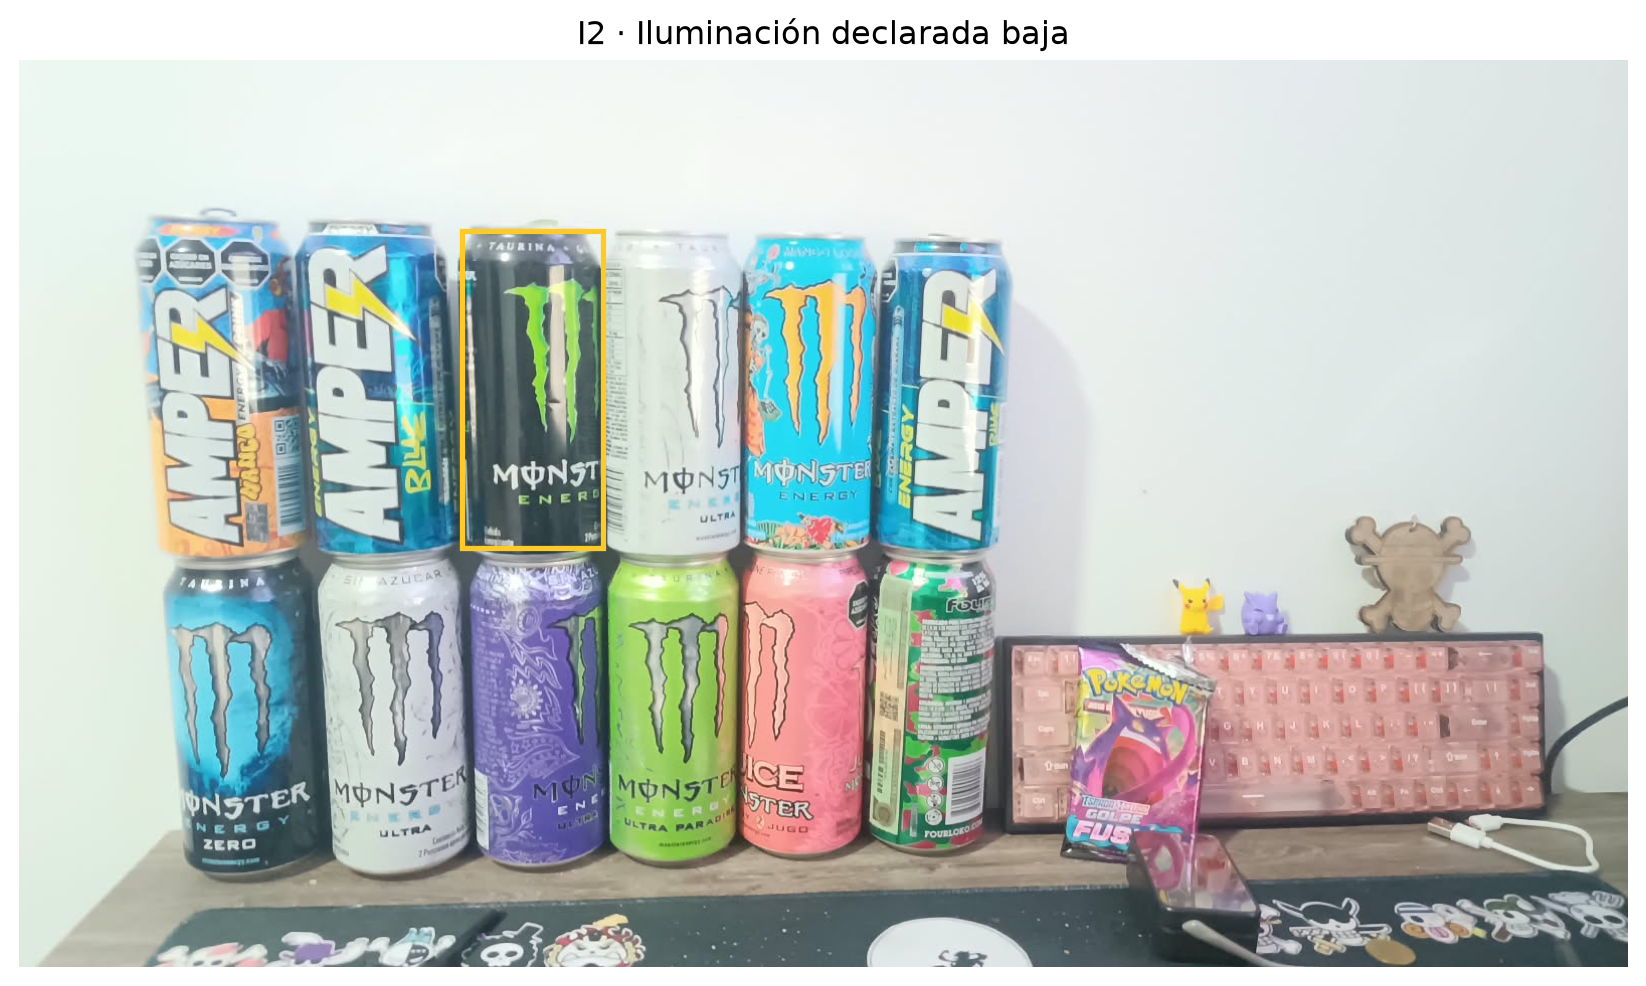

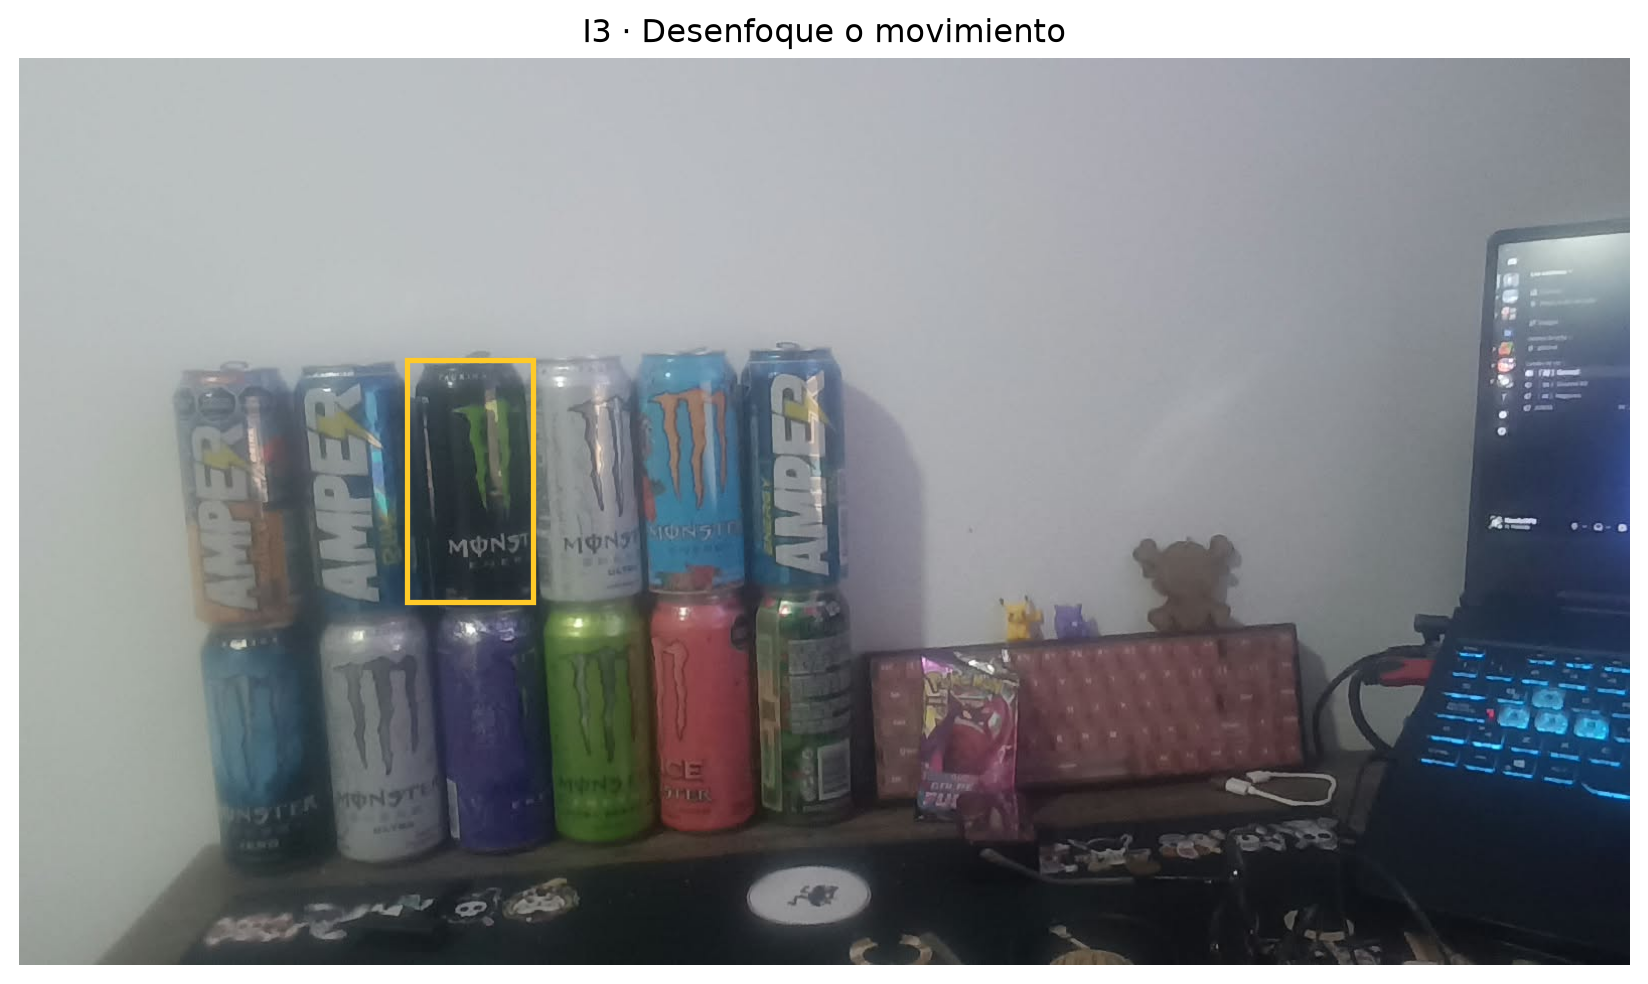

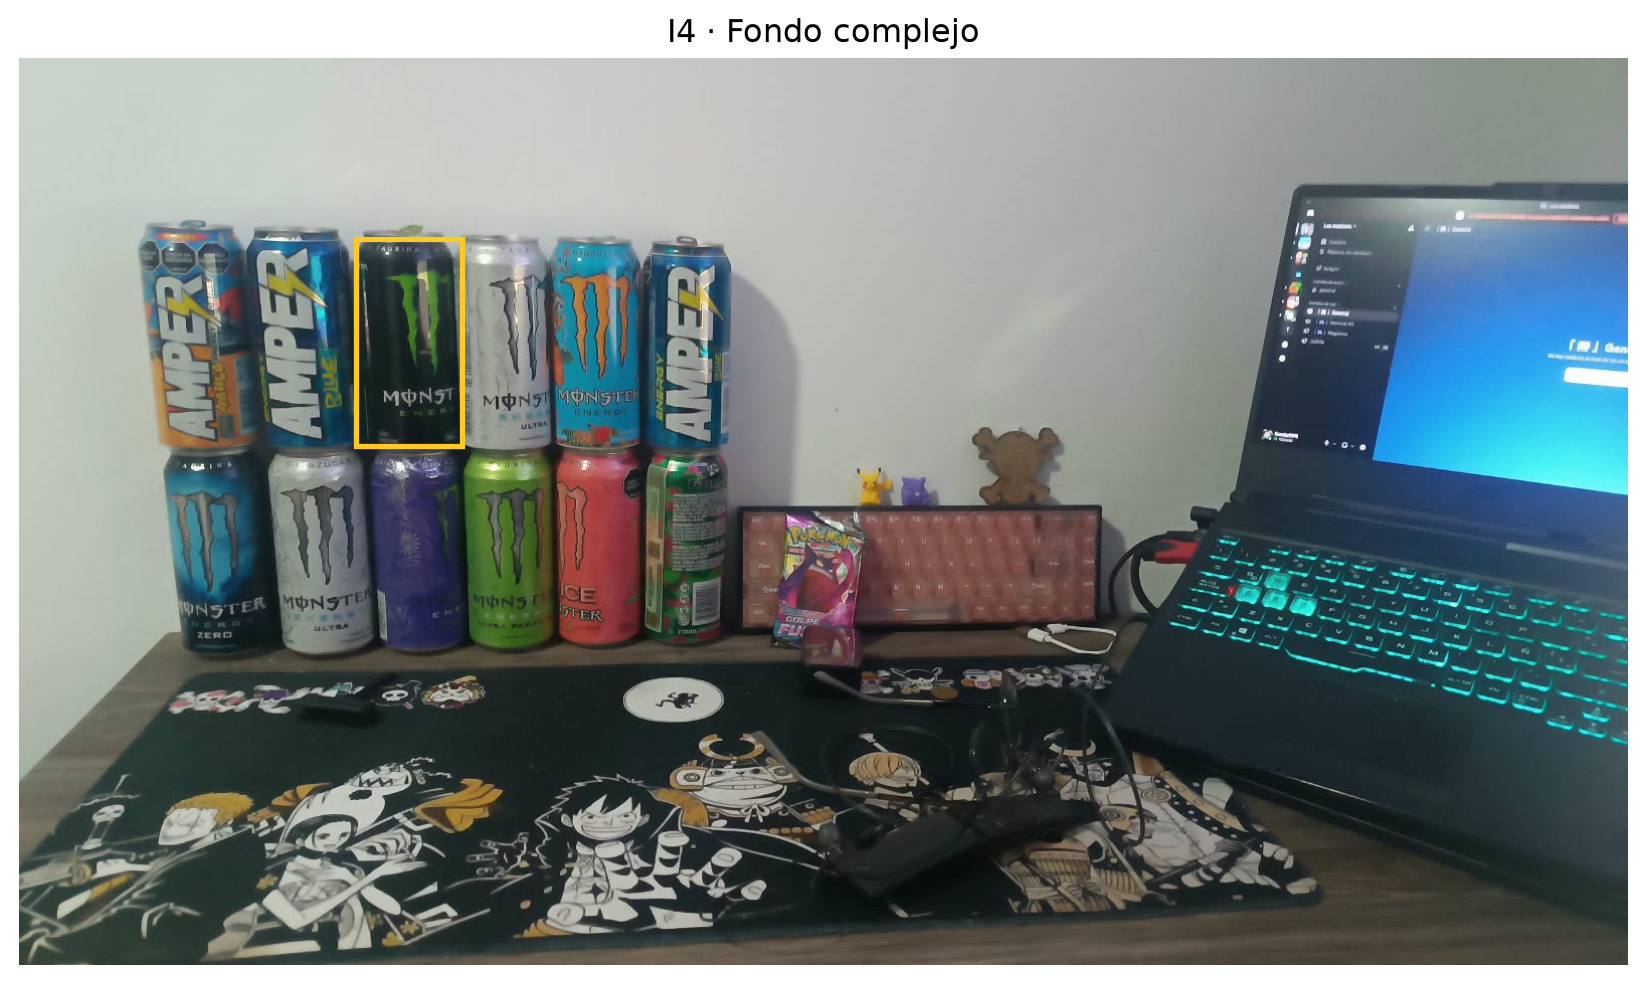

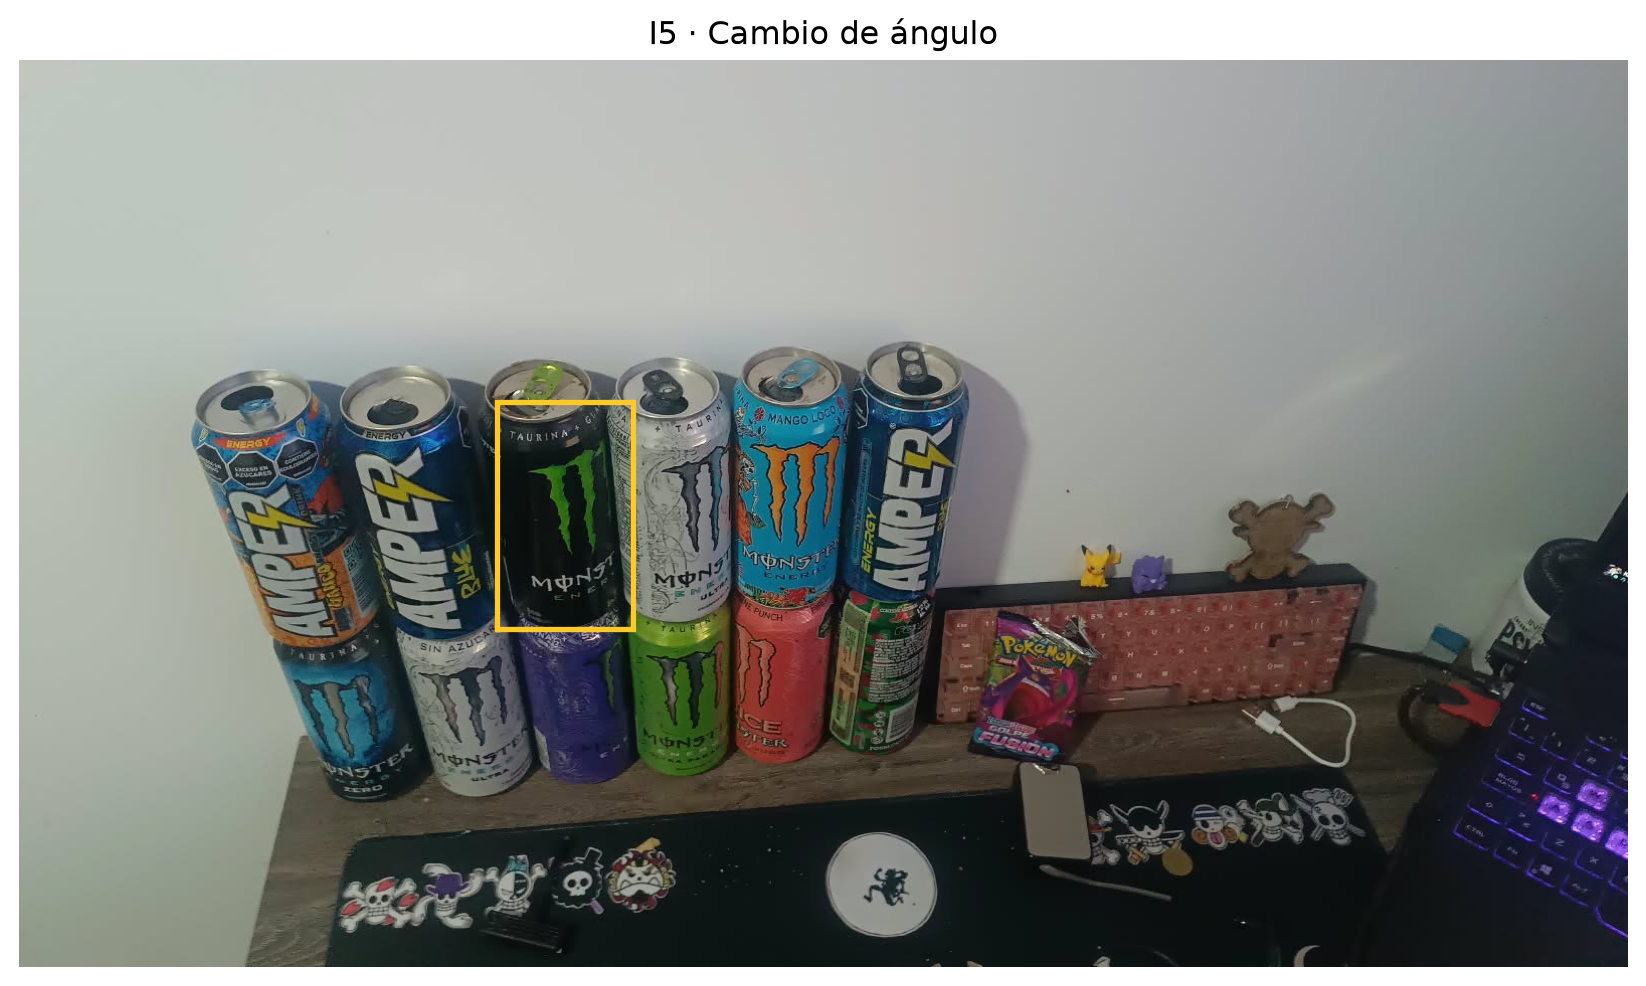

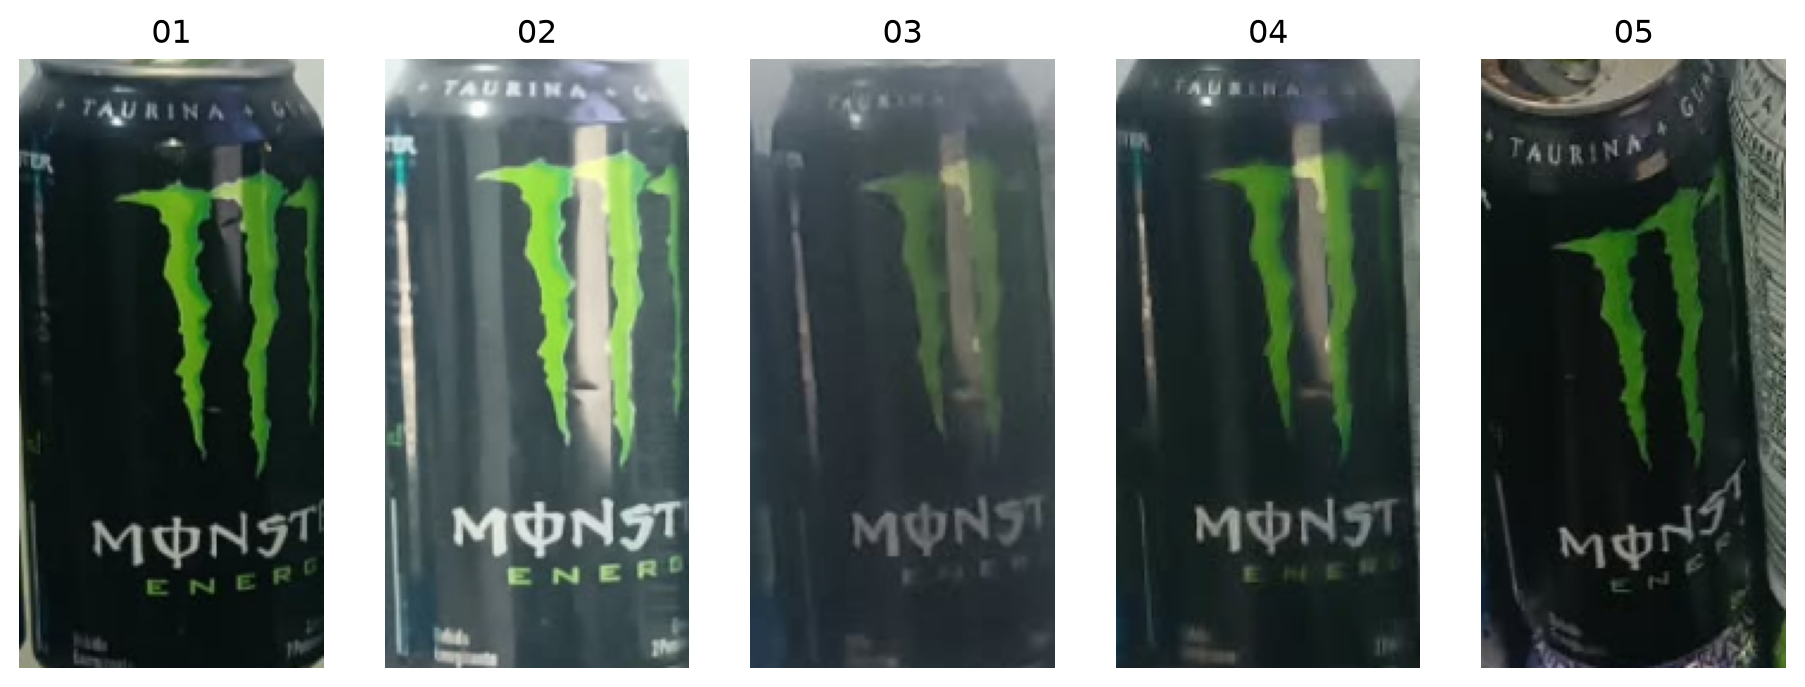

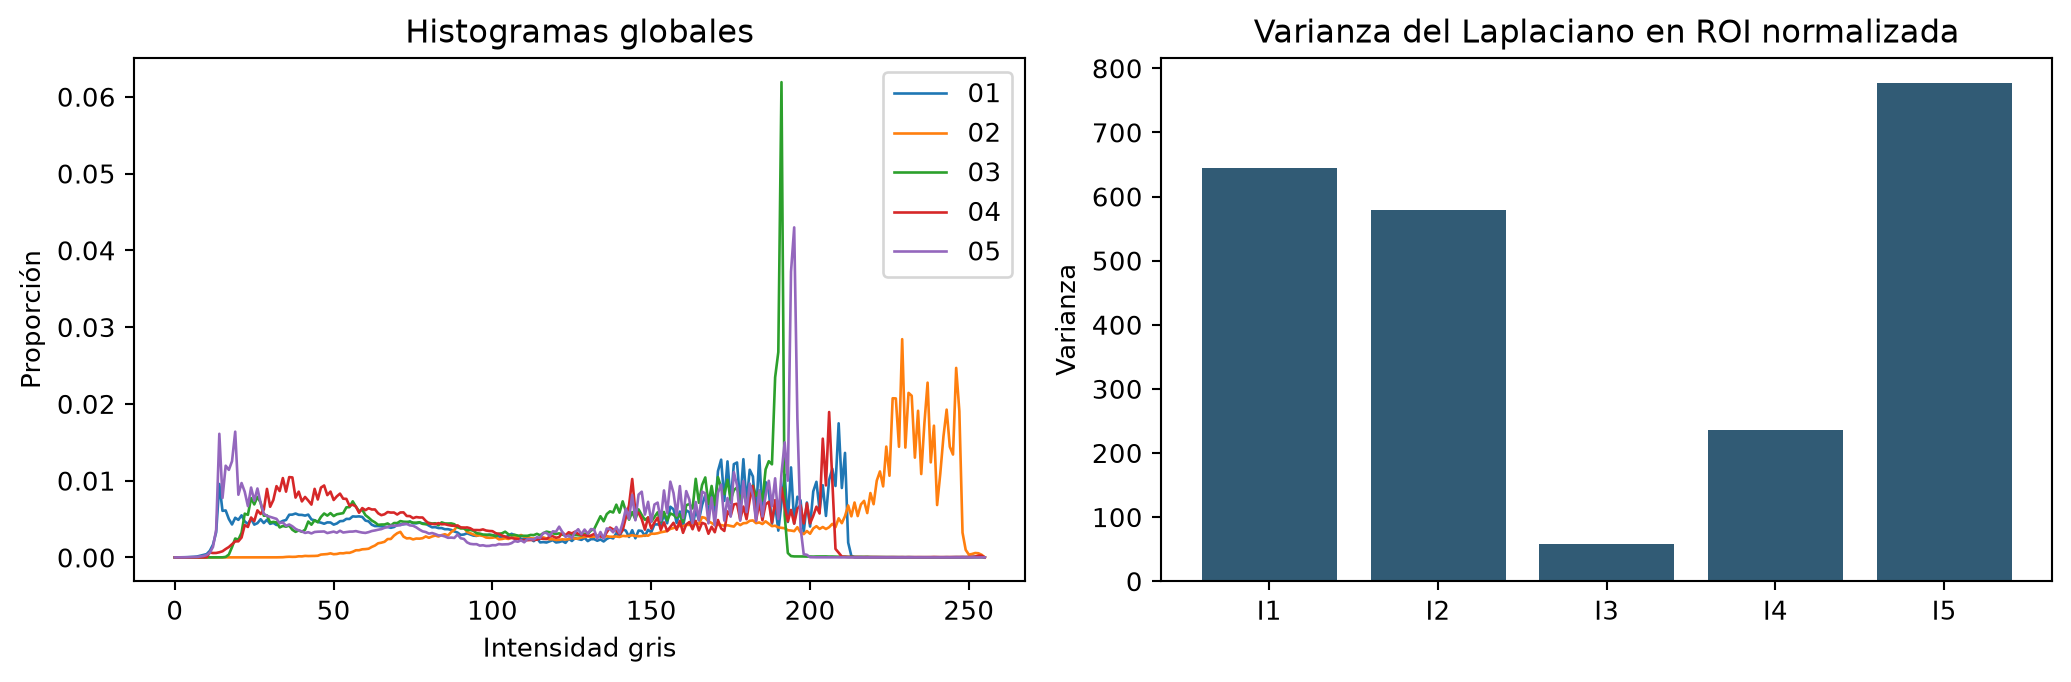

In [4]:
for nombre in ["01_captura.png", "02_captura.png", "03_captura.png", "04_captura.png", "05_captura.png", "06_mismo_objeto.png", "07_diagnostico.png"]:
    display(Image(filename=str(ROOT / "resultados/figuras" / nombre), width=900))

## 4 Comparación de resultados
El aumento del Laplaciano es esperable al realzar bordes; no demuestra recuperación de detalle ni mejora de un clasificador. La fotografía denominada baja iluminación presenta brillo mayor que la referencia. El conjunto no permite verificar una captura físicamente subexpuesta.

cantidad,sigma,recorte_previo_pct,brillo,contraste,laplaciano,tenengrad,oscuros_pct,claros_pct,roi_brillo,roi_contraste,roi_laplaciano,roi_tenengrad,roi_oscuros_pct,roi_claros_pct
0.4,1.2,0.008809655937846836,121.37901845172031,56.81913594196894,97.37763584451231,1989.4024056603773,0.0006243063263041066,0.016301331853496116,69.81386666666667,30.765756197145915,195.14404788888888,3863.0594,0.0,0.0
0.8,1.2,0.0208795782463929,121.33031908990012,56.913320511269525,149.04766146908568,2607.2862902330744,0.005757491675915649,0.024278579356270813,69.81296666666667,31.340491144825553,302.49818292333333,5110.641466666667,0.0,0.0033333333333333335
1.2,1.2,0.04134295227524972,121.33064789123196,57.082841904035035,211.67520997161662,3318.0471309655936,0.022058823529411766,0.0373196448390677,69.80663333333334,31.986118489102253,434.36669407888894,6571.652333333333,0.006666666666666667,0.006666666666666667


estado,brillo,contraste,laplaciano,tenengrad,oscuros_pct,claros_pct
Antes,121.83933546059933,56.63345301783884,54.22782525247056,1456.9280008324085,0.0,0.007838512763596005
Después,121.33031908990012,56.913320511269525,149.04766146908568,2607.2862902330744,0.005757491675915649,0.024278579356270813


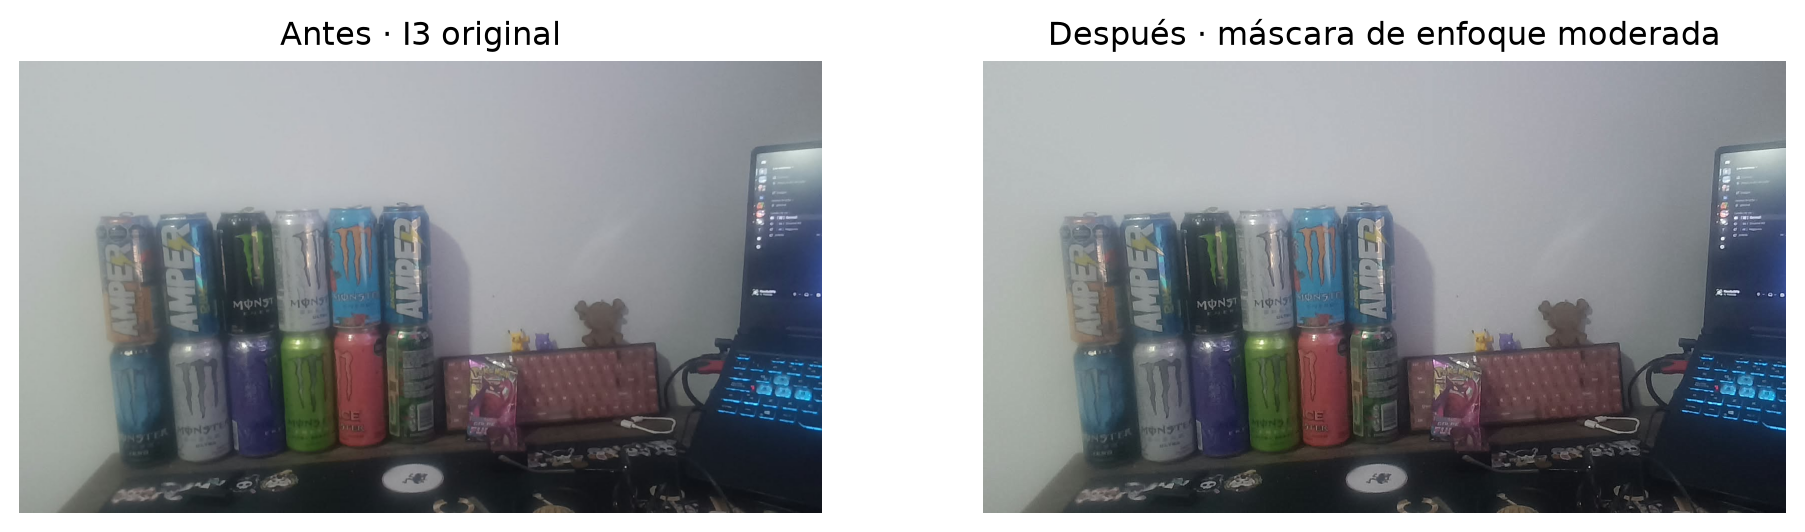

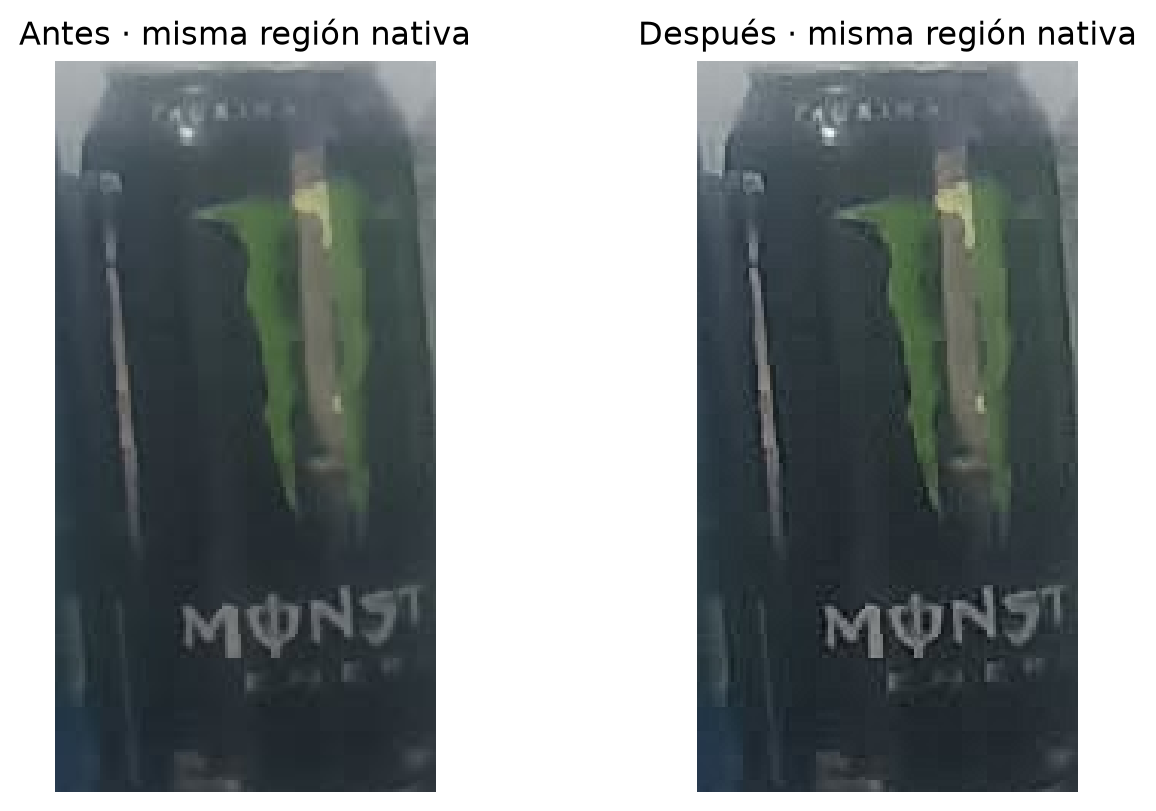

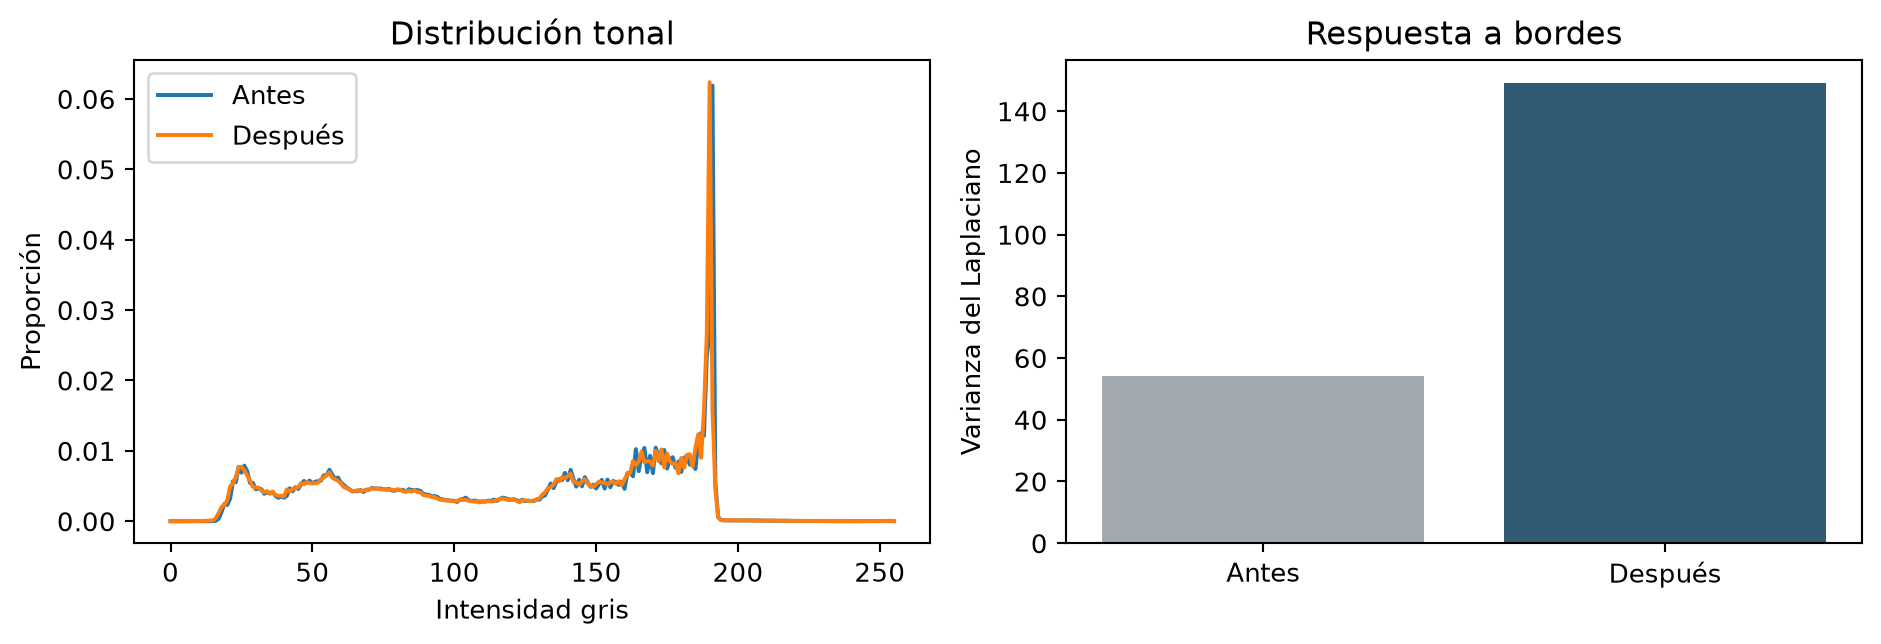

In [5]:
mostrar_tabla("parametros.csv")
mostrar_tabla("antes_despues.csv")
for nombre in ["08_antes_despues.png", "09_detalle.png", "10_evaluacion.png"]:
    display(Image(filename=str(ROOT / "resultados/figuras" / nombre), width=900))

## 5 Conclusiones
El realce mejora de manera moderada la definición visual de bordes conservados, pero la pérdida de detalle fino persiste. Para lectura de etiquetas se recomienda repetir la captura con cámara estable, iluminación uniforme y enfoque sobre la lata. No se calculan PSNR ni SSIM entre fotos distintas porque no existe una referencia nítida alineada de I3.

## Referencias
OpenCV. (s. f.). *Smoothing images*. https://docs.opencv.org/4.13.0/d4/d13/tutorial_py_filtering.html

OpenCV. (s. f.). *Histograms 2 Histogram equalization*. https://docs.opencv.org/4.13.0/d5/daf/tutorial_py_histogram_equalization.html